In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold, cross_val_predict, cross_validate
from sklearn.linear_model import LinearRegression
from scipy.stats import gaussian_kde
from scipy.spatial import cKDTree
import shap 

sys.path.insert(1, '../../ProcessEvents')
from config import CATCHMENT_LOOKUP_DICT, ENSEMBLE_MEMBERS, CATCHMENTS

from PrepDataFunctions import *

### Get event data

In [2]:
df = prep_for_modelling(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo.pkl", 
                        remove_events_with_zero_flooding = False)
df.reset_index(inplace=True, drop=True)
# df[df['max_quartile_index_n'].isnull()][["max_precip", "max_quartile_index_n", "length", "total_acc", "length_of_active_rain"]]
# df = create_subset(df, 10000, 10)
subset_early = create_temporal_subset(df, "before", 2020)

### Create model instances and parameters

In [3]:
rf = RandomForestRegressor(n_estimators=100,max_depth=8,random_state=42)
lr = LinearRegression()
cv_parameters = KFold(n_splits=5, shuffle=True, random_state=42)
error_metrics = ['neg_mean_absolute_error', 'r2', 'neg_root_mean_squared_error', 'neg_mean_absolute_percentage_error']

### Define parameters to use in modelling

In [4]:
my_vars = ['max_precip', 'total_acc',  
                       "hc_at_peak", 'fumax_at_peak', 
                      'se_max', 'se_min',  'sat_at_peak_new', 'sat_at_peak_old',
                      'fu_mean_m',  'fu_min_m', 'fu_max_m', 'fu_at_peak_new', 
                        "mean_sm_2_before_event",
                      #   'peak_position_ratio','d50','gini','time_based_std','dry_ratio','max_quartile_index',
         'peak_position_ratio_n','d50_n','gini_n','time_based_std_n','dry_ratio_n','max_quartile_index_n',                     
                      'peak_cell_slope_avg', 'peak_cell_elev_avg','peak_cell_elev_min','peak_cell_slope_max', 
                      #   'peak_cell_elev_max',
                       'peak_cell_water_prop', 'peak_cell_urban_prop', 'peak_cell_inside_prop',
                   # take these out because highly correlated with max_precip    
                   #"cluster_mean_intensity_t80","cluster_mean_intensity_t50","cluster_mean_intensity_t60",
           # "cluster_mean_intensity_t50", "cluster_mean_intensity_t60", "cluster_mean_intensity_t80",
                #'cluster_rain_total_t50',  'cluster_rain_total_t60','cluster_rain_total_t80', 
           'cluster_n_cells_t50', 'cluster_n_cells_t80',
                      "random_variable"]

# Define X (predictors) and Y (response)
X = subset_early[my_vars]
y = subset_early['10cm_area']

### Define groups of variables with a high level of correlation

In [5]:
corr = subset_early[my_vars].corr(method="spearman")   # your existing line
THRESH = 0.65   

from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
def groups_hierarchical(corr, thresh=0.75, method="average"):
    """Cluster on distance = 1 - |rho|. 'average' needs members to be correlated with each other
    on average (compact groups); 'single' lets chains form (A~B, B~C => A,B,C); 'complete' is strictest
    (every pair in a group must exceed thresh)."""
    dist = (1 - corr.abs().fillna(0)).values.copy()
    np.fill_diagonal(dist, 0)
    Z = linkage(squareform(dist, checks=False), method=method)
    labels = fcluster(Z, t=1 - thresh, criterion="distance")
    return _labels_to_groups(corr.columns, labels)


def groups_connected(corr, thresh=0.75):
    """Link any pair with |rho| >= thresh; each connected component is a group (chaining allowed)."""
    adj = (corr.abs().fillna(0).values >= thresh)
    n, labels = connected_components(adj, directed=False)
    return _labels_to_groups(corr.columns, labels)


def _labels_to_groups(cols, labels):
    out = {}
    for lab in np.unique(labels):
        members = list(cols[labels == lab])
        if len(members) > 1:                      # only report multi-variable groups
            out[f"group_{'_'.join(members[0].split('_')[:2])}"] = members
    return out


groups = groups_hierarchical(corr, THRESH, method="average")
# groups = groups_connected(corr, THRESH)

for name, members in groups.items():
    sub = corr.loc[members, members].abs().values
    min_pair = sub[np.triu_indices_from(sub, 1)].min()
    # print(f"{name}: {members}  (weakest pairwise |rho| = {min_pair:.2f})")
    
new_dict = {}
new_labels = ['Soil Saturation', "Cell slope", "Cell capacity to hold water", "Rainfall temporal profile"]
for label_num,(key, group) in enumerate(groups.items()):
    new_dict[new_labels[label_num]] = group    

### Fit model and assess SHAP values

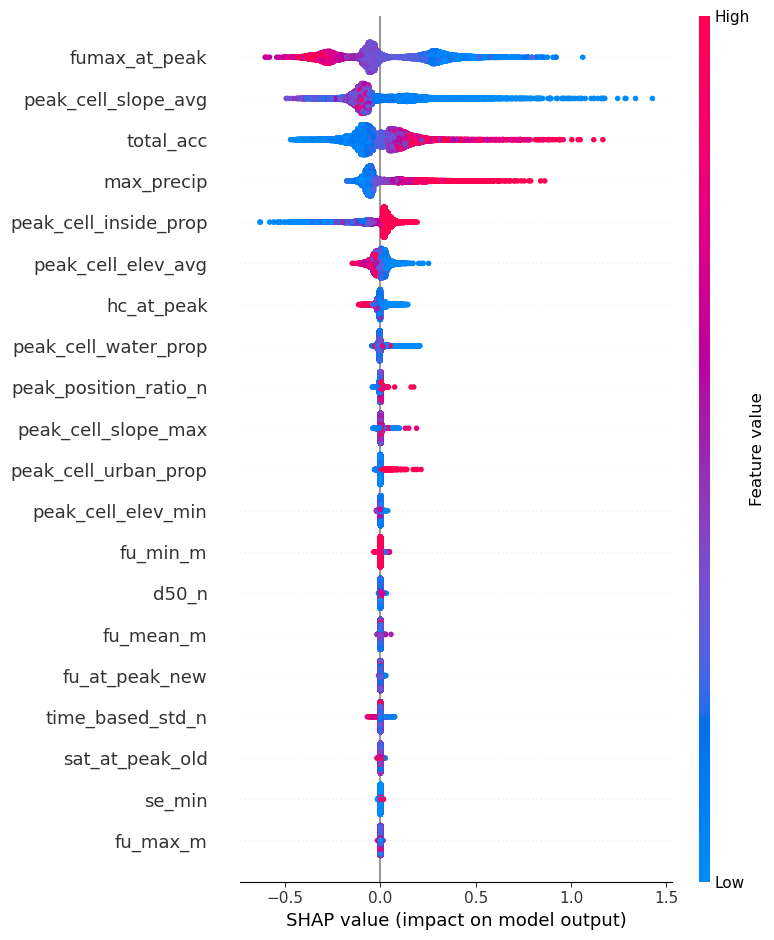

In [6]:
rf.fit(X,y)
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X)
shap.summary_plot(shap_values, X, show=True, max_display=20)

### Assess SHAP values using grouped variables

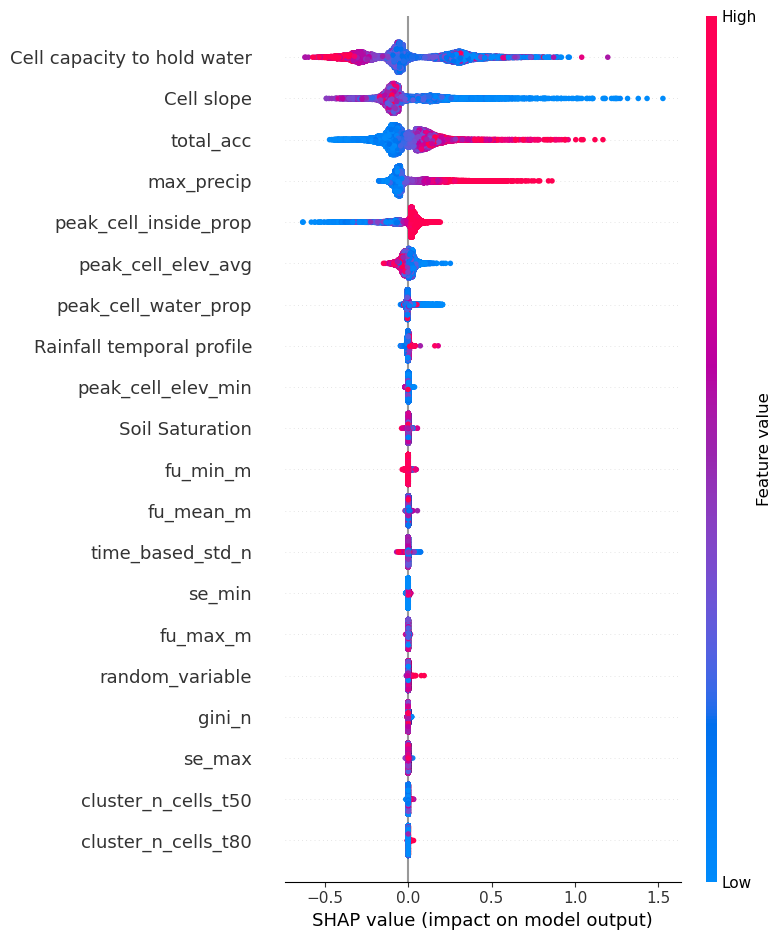

In [7]:
shap_df = pd.DataFrame(shap_values, columns=X.columns, index=X.index)

grouped = {}
used = set()
for name, cols in new_dict.items():
    grouped[name] = shap_df[cols].sum(axis=1)   # SHAP is additive, so group attribution = sum of members
    used.update(cols)
for col in X.columns:
    if col not in used:
        grouped[col] = shap_df[col]
grouped = pd.DataFrame(grouped)

# ---------------------------------------------------------------------------
# 2. Matching "feature values" for colouring the beeswarm: mean of z-scored members
# ---------------------------------------------------------------------------
Xz = (X - X.mean()) / X.std()
group_vals = {}
for name, cols in new_dict.items():
    group_vals[name] = Xz[cols].mean(axis=1)
for col in X.columns:
    if col not in used:
        group_vals[col] = Xz[col]
group_vals = pd.DataFrame(group_vals)[grouped.columns]

# ---------------------------------------------------------------------------
# 3. Plots
# ---------------------------------------------------------------------------
shap.summary_plot(grouped.values, group_vals, show=True, max_display=20)               # beeswarm
#shap.summary_plot(grouped.values, group_vals, plot_type="bar", show=True, max_display=30)  # mean |SHAP|

# Ranking table
#print(grouped.abs().mean().sort_values(ascending=False).round(4))

### Interpret results

1691 low pixels (7.2% of all pixels)
Low-response pixels:  mean observed = 0.000817, mean OOF-predicted = 0.0218
Typical pixels:       mean observed = 0.562, mean OOF-predicted = 0.56

Groups pushing low pixels DOWN relative to rainfall-matched typical pixels (most negative first):
Cell capacity to hold water   -0.4048
Cell slope                    -0.0711
peak_cell_elev_avg            -0.0180
total_acc                     -0.0157
peak_cell_inside_prop         -0.0135
max_precip                    -0.0044
Rainfall temporal profile     -0.0019
peak_cell_elev_min            -0.0006
fu_min_m                      -0.0001
se_max                        -0.0001
dtype: float64


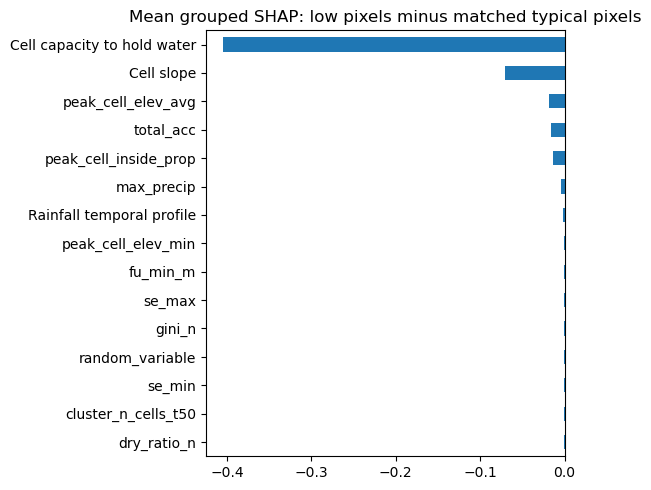


Pixel 1029: observed=0.0018, OOF pred=0.00765, model pred=0.00801


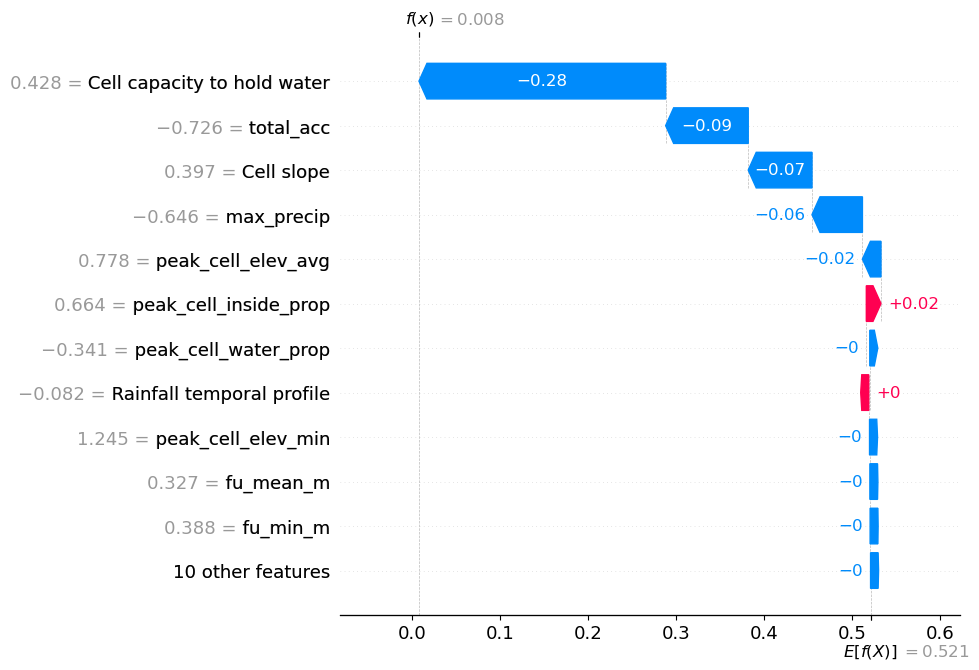


Pixel 1036: observed=0.0036, OOF pred=0.0422, model pred=0.0431


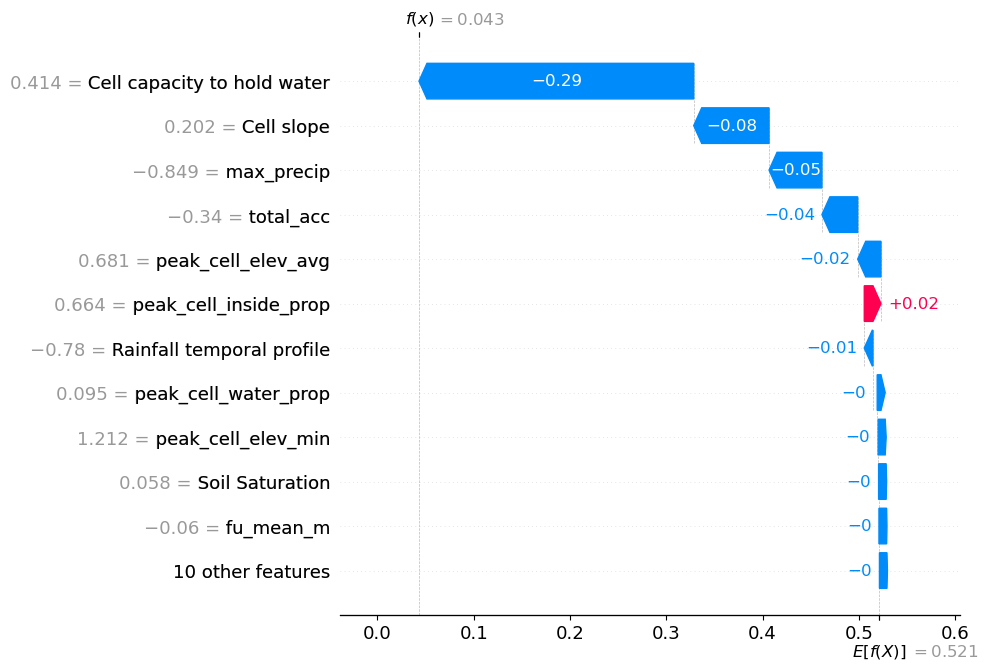


Pixel 1042: observed=0, OOF pred=0.0151, model pred=0.00957


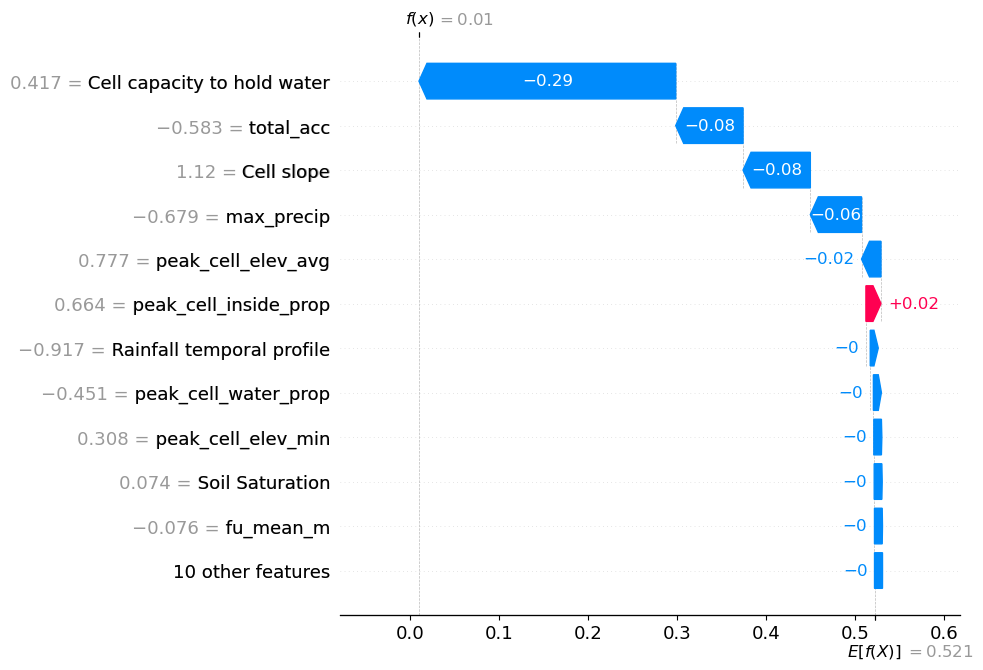


Pixel 1043: observed=0.0018, OOF pred=0.12, model pred=0.141


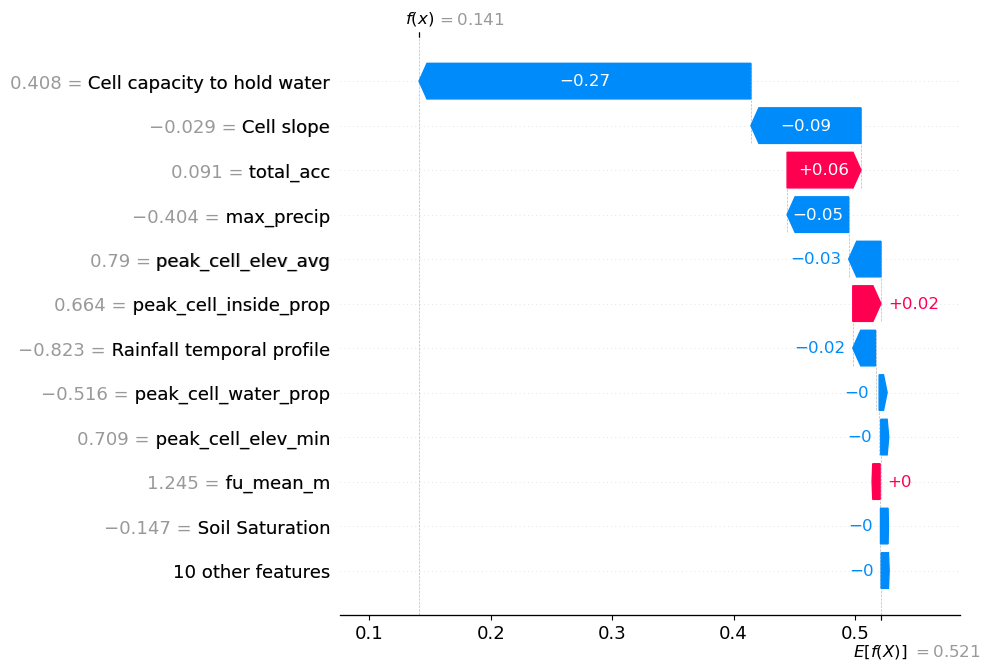


Pixel 1062: observed=0.0018, OOF pred=0.053, model pred=0.0411


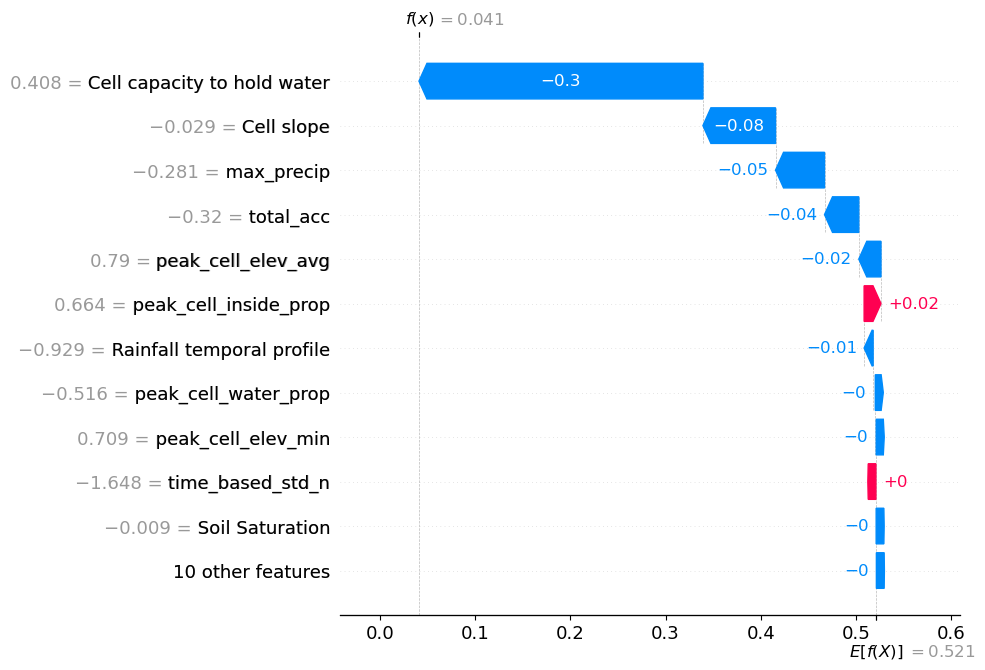


Pixel 1072: observed=0.0018, OOF pred=0.0181, model pred=0.0111


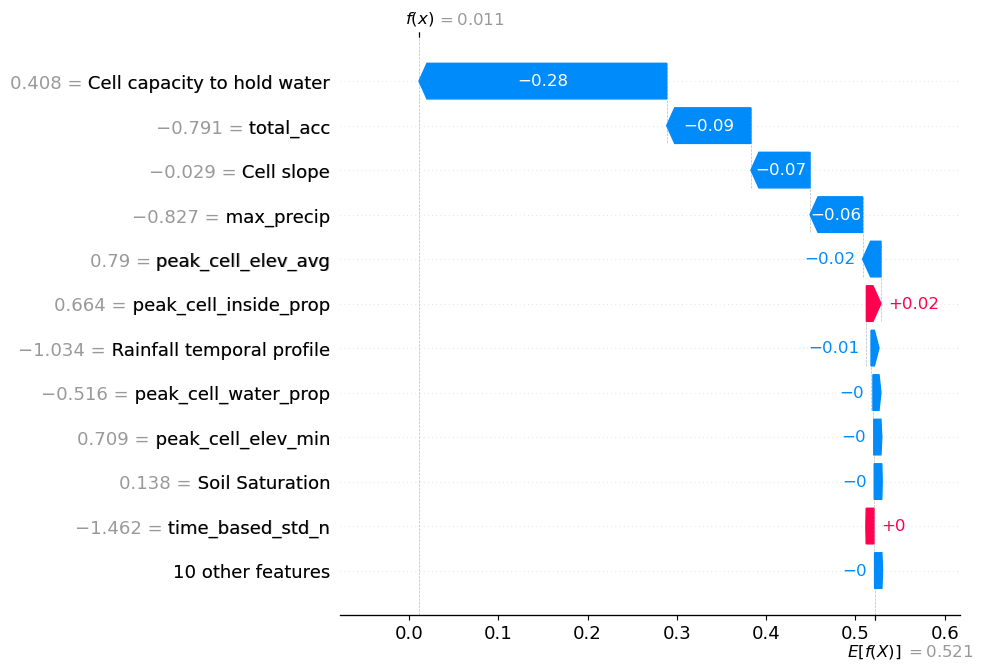


Pixel 1076: observed=0, OOF pred=0.00716, model pred=0.00724


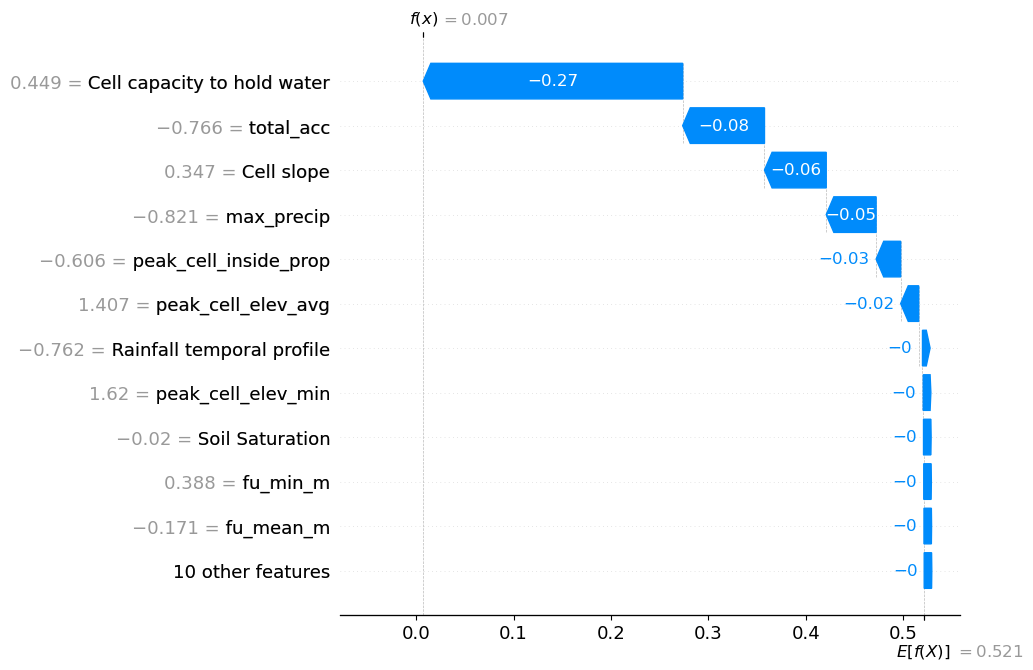


Pixel 1079: observed=0, OOF pred=0.0138, model pred=0.0105


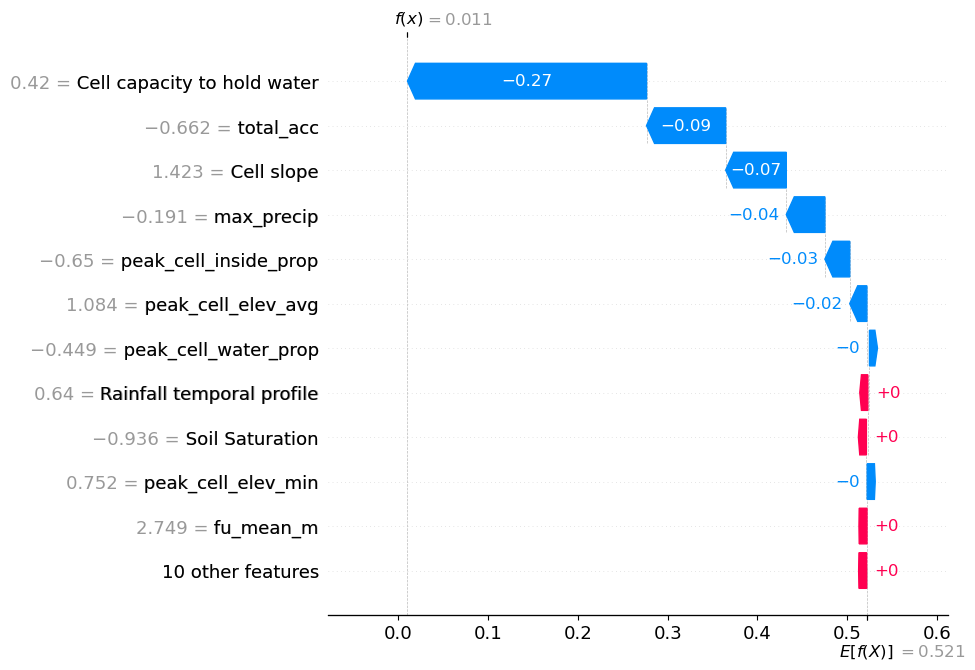


Pixel 1080: observed=0, OOF pred=0.00737, model pred=0.00724


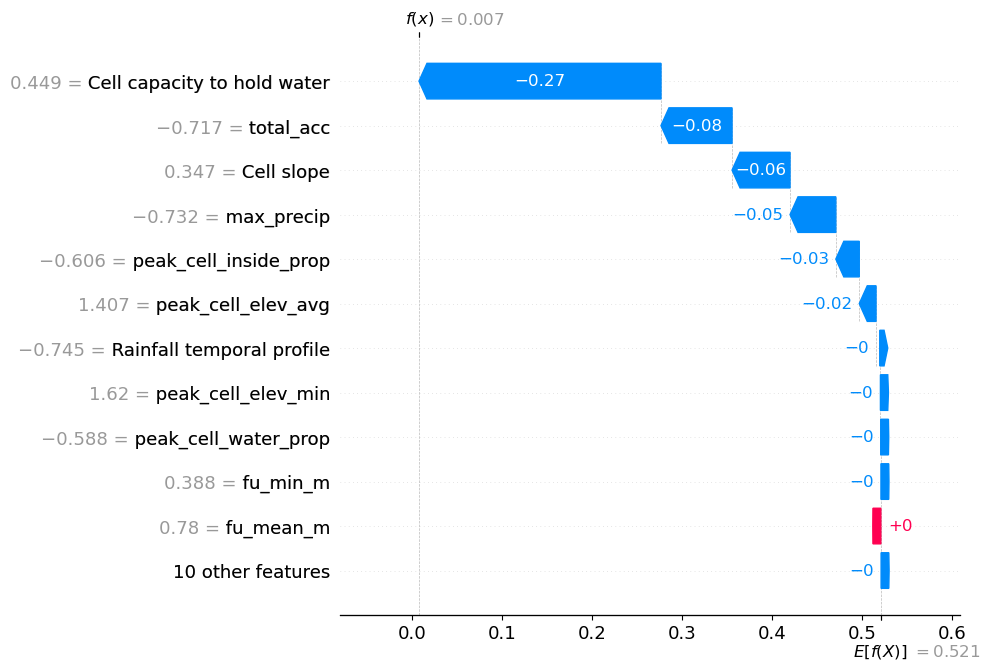


Pixel 1083: observed=0, OOF pred=0.00981, model pred=0.00863


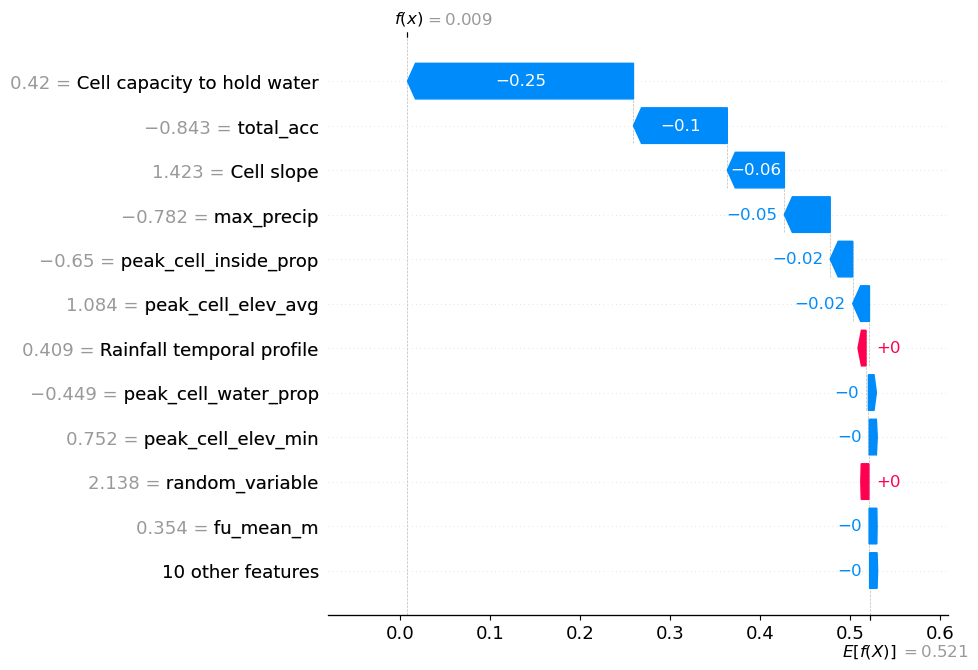


Cell capacity to hold water: percentile of the variable(s) among ALL pixels (median over low pixels)
hc_at_peak              0.95
fumax_at_peak           0.95
peak_cell_urban_prop    0.10

Cell slope: percentile of the variable(s) among ALL pixels (median over low pixels)
peak_cell_slope_avg    0.89
peak_cell_slope_max    0.83

peak_cell_elev_avg: percentile of the variable(s) among ALL pixels (median over low pixels)
peak_cell_elev_avg    0.84

total_acc: percentile of the variable(s) among ALL pixels (median over low pixels)
total_acc    0.33

peak_cell_inside_prop: percentile of the variable(s) among ALL pixels (median over low pixels)
peak_cell_inside_prop    0.35


In [8]:
RAIN_VAR = "max_precip"                      # <- change to your rainfall column
y = pd.Series(np.asarray(y), index=X.index)

# ---------------------------------------------------------------------------
# 1. Find "surprisingly small response for the rainfall" pixels
#    Compare each pixel's response with pixels receiving similar rainfall.
# ---------------------------------------------------------------------------
rain_bin = pd.qcut(X[RAIN_VAR], q=20, duplicates="drop")
pct_within_bin = y.groupby(rain_bin, observed=True).rank(pct=True)      # 0 = lowest response for that rainfall
# low_ids = pct_within_bin.index[pct_within_bin < 0.05]                    # bottom 5% for their rainfall
# ref_ids = pct_within_bin.index[pct_within_bin > 0.50]                    # typical/high responders, same rainfall range
# low_ids = y.index[y <= y.quantile(0.05)] 

THRESH = 0.005
low_ids = y.index[y < THRESH]
ref_ids = y.index[y >= THRESH]       # everything else, used as the comparison group
print(f"{len(low_ids)} low pixels ({len(low_ids) / len(y):.1%} of all pixels)")

# ---------------------------------------------------------------------------
# 2. Is the MODEL right about these pixels? (use out-of-fold predictions)
#    If the model predicts them badly, SHAP explains the model's mistake, not the physics.
# ---------------------------------------------------------------------------
oof = pd.Series(cross_val_predict(rf, X, y, cv=KFold(5, shuffle=True, random_state=0), n_jobs=-1), index=X.index)
print("Low-response pixels:  mean observed = %.3g, mean OOF-predicted = %.3g" % (y[low_ids].mean(), oof[low_ids].mean()))
print("Typical pixels:       mean observed = %.3g, mean OOF-predicted = %.3g" % (y[ref_ids].mean(), oof[ref_ids].mean()))

# ---------------------------------------------------------------------------
# 3. Why are the low pixels low? Contrast SHAP of low pixels against rainfall-matched reference pixels.
#    Match within each rainfall bin so rainfall itself doesn't dominate the contrast.
# ---------------------------------------------------------------------------
diffs = []
for b in rain_bin.cat.categories:
    lo = low_ids.intersection(rain_bin.index[rain_bin == b])
    rf_ = ref_ids.intersection(rain_bin.index[rain_bin == b])
    if len(lo) >= 3 and len(rf_) >= 3:
        diffs.append(grouped.loc[lo].mean() - grouped.loc[rf_].mean())
contrast = pd.concat(diffs, axis=1).mean(axis=1).sort_values()

# contrast = (grouped.loc[low_ids].mean() - grouped.drop(low_ids).mean()).sort_values()

print("\nGroups pushing low pixels DOWN relative to rainfall-matched typical pixels (most negative first):")
print(contrast.head(10).round(4))

contrast.head(15)[::-1].plot.barh(figsize=(6, 5), title="Mean grouped SHAP: low pixels minus matched typical pixels")
plt.tight_layout(); plt.show()

# ---------------------------------------------------------------------------
# 4. Zoom in on single pixels: waterfall (where does this prediction come from?)
# ---------------------------------------------------------------------------
base = explainer.expected_value
base = float(np.ravel(base)[0])
explanation = shap.Explanation(values=grouped.values, base_values=np.full(len(grouped), base),
                               data=group_vals.values, feature_names=list(grouped.columns))
for pid in low_ids[:10]:                                     # a few example pixels
    i = X.index.get_loc(pid)
    print(f"\nPixel {pid}: observed={y[pid]:.3g}, OOF pred={oof[pid]:.3g}, model pred={rf.predict(X.loc[[pid]])[0]:.3g}")
    shap.plots.waterfall(explanation[i], max_display=12, show=True)
    
# ---------------------------------------------------------------------------
# 5. Raw values behind the story: where do the low pixels sit in the distribution of each driver?
# ---------------------------------------------------------------------------
top_groups = contrast.index[:5]
for g in top_groups:
    cols = [g] if g in X.columns else new_dict[g]
    pct = X[cols].rank(pct=True)
    print(f"\n{g}: percentile of the variable(s) among ALL pixels (median over low pixels)")
    print(pct.loc[low_ids].median().round(2).to_string())

# Dependence plot for a driver: does the low-response cluster sit in a particular region?
# shap.dependence_plot("some_feature", shap_df.values, X, interaction_index=RAIN_VAR)

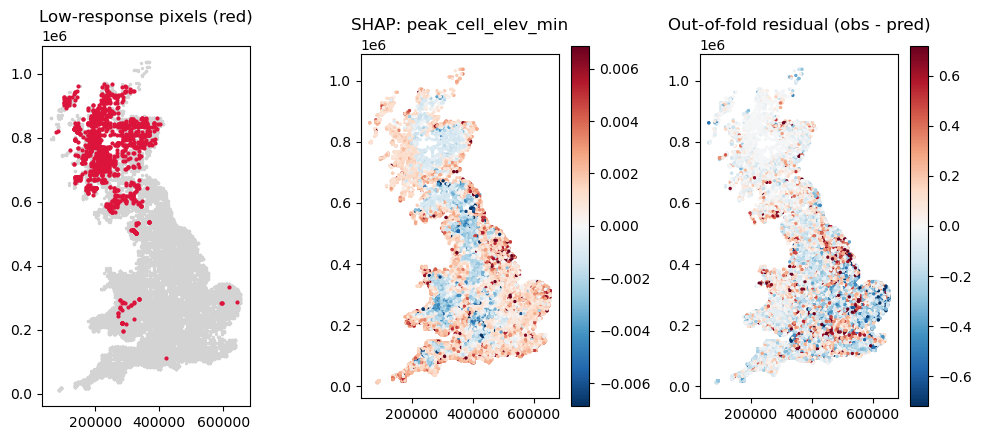

Moran's I  observed response            I =  0.661   p = 0.001
Moran's I  model residual               I =  0.432   p = 0.001
Moran's I  SHAP peak_cell_elev_min      I =  0.659   p = 0.001
Moran's I  low-pixel flag (0/1)         I =  0.544   p = 0.001


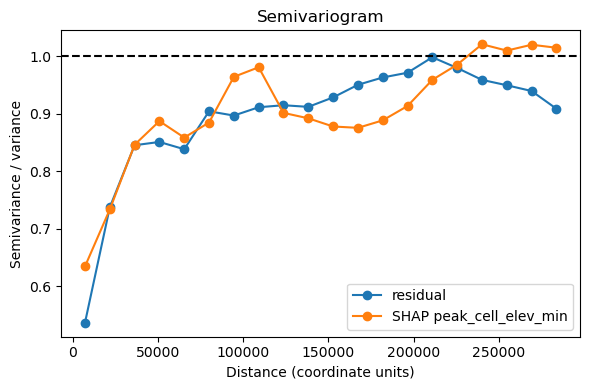

In [19]:
"""
Check spatial structure of (a) flagged low-response pixels, (b) SHAP contributions, (c) model residuals.
Continues from pixel_investigation.py: needs X, y, oof, low_ids, grouped, contrast.
Set XCOL/YCOL to the coordinate columns (projected, metres e.g. British National Grid).
`coords` must be indexed like X.
"""


XCOL, YCOL = "x_coord", "y_coord"                        # <- change; if coords live in df: coords = df.loc[X.index, [XCOL, YCOL]]
coords = subset_early.loc[subset_early.index, [XCOL, YCOL]]
xy = coords.values

# ---------------------------------------------------------------------------
# 1. MAPS: where are the flagged pixels, the top SHAP group, and the model errors?
# ---------------------------------------------------------------------------
top_group = contrast.index[7]
resid = y - oof
flag = subset_early.index.isin(low_ids)

fig, ax = plt.subplots(1, 3, figsize=(10, 4.5))
ax[0].scatter(xy[~flag, 0], xy[~flag, 1], s=2, c="lightgrey")
ax[0].scatter(xy[flag, 0], xy[flag, 1], s=4, c="crimson"); ax[0].set_title("Low-response pixels (red)")
v = grouped[top_group].values; lim = np.nanpercentile(np.abs(v), 98)
s1 = ax[1].scatter(xy[:, 0], xy[:, 1], s=2, c=v, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax[1].set_title(f"SHAP: {top_group}"); plt.colorbar(s1, ax=ax[1])
r = resid.values; lim = np.nanpercentile(np.abs(r), 98)
s2 = ax[2].scatter(xy[:, 0], xy[:, 1], s=2, c=r, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax[2].set_title("Out-of-fold residual (obs - pred)"); plt.colorbar(s2, ax=ax[2])
for a in ax: a.set_aspect("equal")
plt.tight_layout(); plt.show()

# ---------------------------------------------------------------------------
# 2. GLOBAL MORAN'S I with a permutation test (KNN weights, no extra packages)
#    I > 0: similar values cluster; ~0: random; < 0: checkerboard.
# ---------------------------------------------------------------------------
def morans_i(values, xy, k=8, n_perm=999, seed=0):
    values = np.asarray(values, float)
    ok = np.isfinite(values); values, xy = values[ok], xy[ok]
    nbr = cKDTree(xy).query(xy, k=k + 1)[1][:, 1:]            # k nearest neighbours, excluding self
    z = values - values.mean()
    def stat(zv): return (zv * zv[nbr].mean(axis=1)).sum() / (zv ** 2).sum()   # row-standardised weights
    I = stat(z)
    rng = np.random.default_rng(seed)
    perm = np.array([stat(rng.permutation(z)) for _ in range(n_perm)])
    p = (np.sum(np.abs(perm) >= abs(I)) + 1) / (n_perm + 1)
    return I, p

for name, vals in {"observed response": y.values, "model residual": resid.values,
                   f"SHAP {top_group}": grouped[top_group].values,
                   "low-pixel flag (0/1)": flag.astype(float)}.items():
    I, p = morans_i(vals, xy)
    print(f"Moran's I  {name:28s} I = {I:6.3f}   p = {p:.3f}")

# ---------------------------------------------------------------------------
# 3. SEMIVARIOGRAM: over what distance are values similar? (subsample for speed)
# ---------------------------------------------------------------------------
def variogram(values, xy, n_sub=3000, n_bins=20, max_dist=None, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(values), min(n_sub, len(values)), replace=False)
    v, p = np.asarray(values)[idx], xy[idx]
    d = np.sqrt(((p[:, None, :] - p[None, :, :]) ** 2).sum(-1))
    g = 0.5 * (v[:, None] - v[None, :]) ** 2
    iu = np.triu_indices(len(v), 1); d, g = d[iu], g[iu]
    max_dist = max_dist or np.percentile(d, 50)
    bins = np.linspace(0, max_dist, n_bins + 1)
    which = np.digitize(d, bins) - 1
    return (bins[:-1] + bins[1:]) / 2, np.array([g[which == b].mean() if np.any(which == b) else np.nan for b in range(n_bins)])

plt.figure(figsize=(6, 4))
for name, vals in {"residual": resid.values, f"SHAP {top_group}": grouped[top_group].values}.items():
    h, gam = variogram(vals, xy)
    plt.plot(h, gam / np.nanvar(vals), "o-", label=name)         # normalised by variance: 1 = no spatial correlation
plt.axhline(1, c="k", ls="--"); plt.xlabel("Distance (coordinate units)"); plt.ylabel("Semivariance / variance")
plt.legend(); plt.title("Semivariogram"); plt.tight_layout(); plt.show()

# ---------------------------------------------------------------------------
# 4. LOCAL clusters (hot/cold spots) of the flag, optional: pip install esda libpysal
# ---------------------------------------------------------------------------
# from libpysal.weights import KNN
# from esda.moran import Moran_Local
# w = KNN.from_array(xy, k=8); w.transform = "r"
# lisa = Moran_Local(resid.values, w, permutations=999, seed=0)
# sig_cluster = (lisa.p_sim < 0.05) & (lisa.q == 3)       # q==3: low-low residual clusters (model over-predicts)